# Quantum SVM — Iris Dataset


## Librerias

In [23]:
# 1. Import all libraries
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from joblib import Parallel, delayed
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(123)


## Data

In [24]:
data = pd.DataFrame(datasets.load_iris().data, columns=datasets.load_iris().feature_names)
data['target'] = datasets.load_iris().target
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [25]:
data.target.unique()

array([0, 1, 2])

## Data Preparation

In [26]:
n_qubits = 4

X = data.drop(columns='target')
y = data['target']

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")

# Normalize to [0, π]
minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train)
X_test = minmax.transform(X_test)
X_test = np.clip(X_test, 0, np.pi)

print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Custom Dataset Loaded: Train=90, Test=60
Final shapes -> Train: (90, 4), Test: (60, 4)


## Quantum SVM

### Physical Point to Quantum State

In [27]:
# 3. QSVM circuit definition
n_qubits = 4
device = qml.device('lightning.qubit', wires=n_qubits)

@qml.qnode(device)
# ZZ Feature Map
def get_quantum_state(x):
    for _ in range(2):
        for i in range(n_qubits):
            qml.Hadamard(wires=i)
            qml.RZ(2 * x[i], wires=i)
        for i in range(n_qubits - 1):
            for j in range(i + 1, n_qubits):
                qml.CNOT(wires=[i, j])
                qml.RZ(2 * (np.pi - x[i]) * (np.pi - x[j]), wires=j)
                qml.CNOT(wires=[i, j])
    return qml.state()

In [28]:
# 4. Model definition
class FastQSVM:
    def __init__(self, n_jobs=-1):
        # n_jobs=-1 automatically uses all CPU cores
        self.svm = SVC(kernel="precomputed", random_state=42)
        self.n_jobs = n_jobs
        self.train_states = None 
        
    def _compute_states(self, X):
        states = Parallel(n_jobs=self.n_jobs)(delayed(get_quantum_state)(x) for x in X)
        return np.array(states)

    def fit(self, X, y):
        self.train_states = self._compute_states(X)
        # Kernel cuantico
        K_train = np.abs(self.train_states.conj().dot(self.train_states.T)) ** 2
        self.svm.fit(K_train, y)
        return self

    def predict(self, X):
        X_states = self._compute_states(X)
        # Kernel cuantico
        K_test = np.abs(X_states.conj().dot(self.train_states.T)) ** 2
        return self.svm.predict(K_test)
        
    def decision_function(self, X):
        X_states = self._compute_states(X)
        K_test = np.abs(X_states.conj().dot(self.train_states.T)) ** 2
        return self.svm.decision_function(K_test)

In [29]:
# 3–4. QSVM con ZZFeatureMap de Qiskit
n_qubits = 4
feature_map = zz_feature_map(
    feature_dimension=n_qubits,
    reps=2,
    entanglement="full",
)
quantum_kernel = FidelityStatevectorKernel(feature_map=feature_map)

class FastQSVM:
    def __init__(self):
        self.svm = SVC(kernel=quantum_kernel.evaluate, random_state=42)

    def fit(self, X, y):
        self.svm.fit(X, y)
        return self

    def predict(self, X):
        return self.svm.predict(X)

    def decision_function(self, X):
        return self.svm.decision_function(X)

## Entrenamiento QSVM


In [30]:
# Training and timing statistics
print("=== Train QSVM  ===")
qsvm_model = FastQSVM()
start = time.time()
qsvm_model.fit(X_train, y_train)
qsvm_time = time.time() - start
print(f"QSVM training time: {qsvm_time:.2f}s")


=== Train QSVM  ===
QSVM training time: 0.07s


## Model Evaluation

In [31]:
def evaluate(model, X_t, y_t, classes):
    preds = model.predict(X_t)
    scores = model.decision_function(X_t)

    acc = accuracy_score(y_t, preds)
    prec = precision_score(y_t, preds, average="macro", zero_division=0)
    rec = recall_score(y_t, preds, average="macro", zero_division=0)
    f1 = f1_score(y_t, preds, average="macro", zero_division=0)
    auc = roc_auc_score(label_binarize(y_t, classes=classes), scores, average="macro")
    return acc, prec, rec, f1, auc, scores, preds

In [32]:
classes = np.unique(y_train)

qsvm_acc, qsvm_prec, qsvm_rec, qsvm_f1, qsvm_auc, qsvm_probs, qsvm_preds = evaluate(
    qsvm_model, X_test, y_test, classes
)
qsvm_acc_tr, qsvm_prec_tr, qsvm_rec_tr, qsvm_f1_tr, qsvm_auc_tr, _, _ = evaluate(
    qsvm_model, X_train, y_train, classes
)

print("\n=== Train vs Test ===")
print(
    f"QSVM Train - Acc: {qsvm_acc_tr:.4f} | Prec: {qsvm_prec_tr:.4f} | Rec: {qsvm_rec_tr:.4f} | "
    f"F1: {qsvm_f1_tr:.4f} | AUC: {qsvm_auc_tr:.4f}"
)
print(
    f"QSVM Test  - Acc: {qsvm_acc:.4f} | Prec: {qsvm_prec:.4f} | Rec: {qsvm_rec:.4f} | "
    f"F1: {qsvm_f1:.4f} | AUC: {qsvm_auc:.4f}"
)



=== Train vs Test ===
QSVM Train - Acc: 0.9667 | Prec: 0.9697 | Rec: 0.9667 | F1: 0.9670 | AUC: 0.9981
QSVM Test  - Acc: 0.7333 | Prec: 0.7433 | Rec: 0.7333 | F1: 0.7304 | AUC: 0.8825


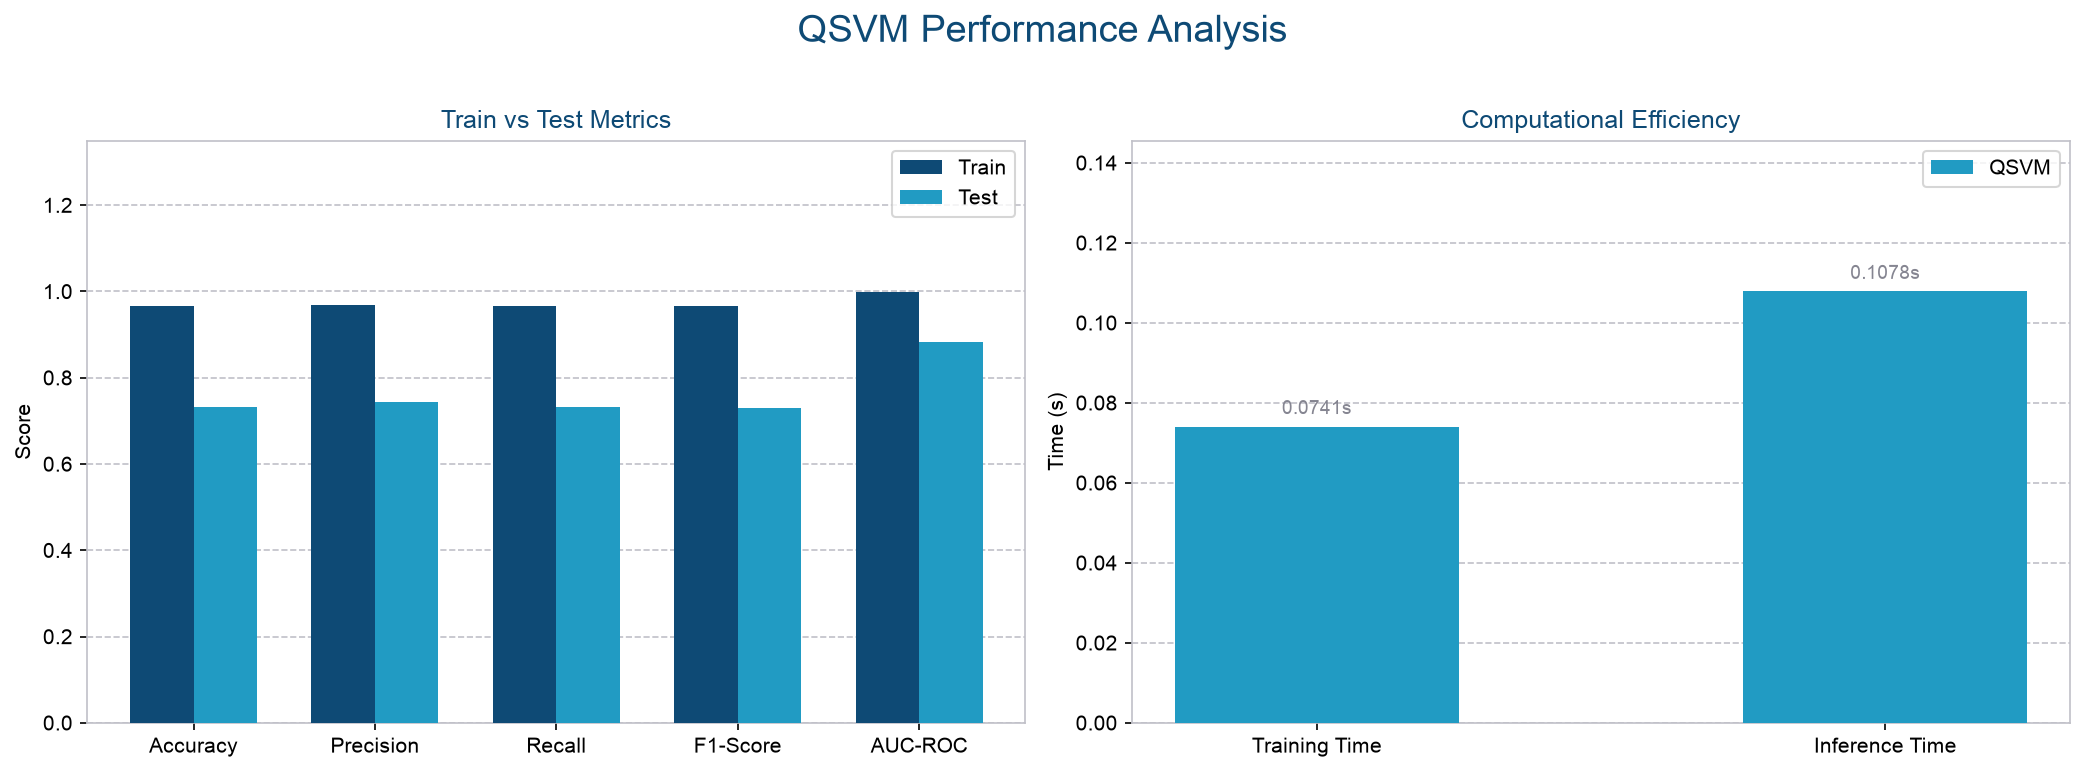

In [33]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    'font.sans-serif': ['Arial'],
    'axes.edgecolor': '#C0C0C8',
    'grid.color': '#C0C0C8',
    'grid.linestyle': '--'
})

def get_inference_time(model, data):
    start = time.time()
    _ = model.predict(data)
    return time.time() - start

qsvm_inf_time = get_inference_time(qsvm_model, X_test)

train_color = '#0E4A75'
test_color = '#219BC3'
unir_gris = '#858591'

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle('QSVM Performance Analysis', fontsize=18, y=1.02, color='#0E4A75')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
train_vals = [qsvm_acc_tr, qsvm_prec_tr, qsvm_rec_tr, qsvm_f1_tr, qsvm_auc_tr]
test_vals = [qsvm_acc, qsvm_prec, qsvm_rec, qsvm_f1, qsvm_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width/2, train_vals[i], width, color=train_color,
               label='Train' if i == 0 else '', zorder=3)
    axs[0].bar(x[i] + width/2, test_vals[i], width, color=test_color,
               label='Test' if i == 0 else '', zorder=3)

axs[0].set_ylabel('Score')
axs[0].set_title('Train vs Test Metrics', color='#0E4A75')
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc='upper right')
axs[0].grid(axis='y', zorder=0)

eff_labels = ['Training Time', 'Inference Time']
qsvm_eff = [qsvm_time, qsvm_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, qsvm_eff, 0.5, color=test_color, label='QSVM', zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel('Time (s)')
axs[1].set_title('Computational Efficiency', color='#0E4A75')
max_time = max(qsvm_eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc='upper right')
axs[1].grid(axis='y', zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], qsvm_eff[i] + offset, f'{qsvm_eff[i]:.4f}s',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [ ]:
# Save metrics for ClassicalClassification comparison
import json
from pathlib import Path

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/ClassicalClassification/metrics."""
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        classical = base / "Notebooks" / "ClassicalClassification"
        if classical.is_dir():
            metrics_dir = classical / "metrics"
            metrics_dir.mkdir(parents=True, exist_ok=True)
            return metrics_dir
    metrics_dir = Path.cwd().resolve() / "Notebooks" / "ClassicalClassification" / "metrics"
    metrics_dir.mkdir(parents=True, exist_ok=True)
    return metrics_dir

metrics_dir = resolve_metrics_dir()

payload = {
    "model": "QSVM",
    "family": "quantum",
    "protocol": {
        "dataset": "iris",
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
    },
    "train": {
        "accuracy": float(qsvm_acc_tr),
        "precision": float(qsvm_prec_tr),
        "recall": float(qsvm_rec_tr),
        "f1": float(qsvm_f1_tr),
        "auc": float(qsvm_auc_tr),
    },
    "test": {
        "accuracy": float(qsvm_acc),
        "precision": float(qsvm_prec),
        "recall": float(qsvm_rec),
        "f1": float(qsvm_f1),
        "auc": float(qsvm_auc),
    },
    "train_time_s": float(qsvm_time),
    "inference_time_s": float(qsvm_inf_time),
}

out = metrics_dir / "qsvm_iris.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)
